# Analysis of Pumping-Test Recovery Using the Theis Method

**Hydraulic Methods · Hydrogeology · Karlsruhe Institute of Technology (KIT)**

This notebook explains **water-level recovery after pumping stops** using the superposition principle and the **Theis recovery straight-line method**.

**Learning objectives:**

- distinguish recovery from **residual drawdown**;
- correctly identify the time variables **t**, **t′**, and **tₚ**;
- apply the semi-logarithmic recovery straight-line method;
- estimate **transmissivity T** from the slope and assess the quality of fit.

**Required packages:** `numpy` and `matplotlib`. All input data appear in separate code cells and can be replaced with measurements from other pumping tests.

## 1. Theoretical background

### 1.1 Drawdown, recovery and residual drawdown

During pumping, the groundwater level declines; after pumping ceases, it rises. The analysis uses **residual drawdown sᵣ**: the difference between the **initial static water level** and the groundwater level measured at a given time **after pump shutdown**. Residual drawdown decreases during recovery and ideally approaches zero.

**Time definitions:**

- **tₚ**: pumping duration before shutdown [s]
- **t′**: time elapsed since shutdown [s]
- **t = tₚ + t′**: time elapsed since pumping began [s]

In the recovery equation, **t** is not simply the pumping duration **tₚ**.

### 1.2 Superposition principle

Pump shutdown can be represented mathematically by superimposing a **hypothetical injection of equal magnitude** on the original pumping rate, beginning at the time of shutdown. Applying the logarithmic late-time approximation then leads to the recovery straight-line method. Evaluating the complete Theis well function is not required for this method.

**Model assumptions:** confined, homogeneous and sufficiently extensive aquifer; constant pumping rate **Q** until shutdown; approximately radial flow; constant aquifer properties; negligible additional influences (e.g. well losses, aquifer boundaries and wellbore storage).

### 1.3 Recovery straight-line method

For sufficiently late times, the **residual drawdown sᵣ** is approximated by

$$
\boxed{s_r\approx\frac{Q}{4\pi T}\ln\!\left(\frac{t}{t'}\right)
=\frac{Q\ln(10)}{4\pi T}\log_{10}\!\left(\frac{t}{t'}\right)}.
$$

Here, **Q** is the pumping rate [m³/s] and **T** is the transmissivity [m²/s].

A plot of **sᵣ** on a linear axis against the **time ratio t/t′** on a logarithmic axis ideally yields a straight line. For the slope **m** per logarithmic cycle,

$$
\boxed{m=\frac{Q\ln(10)}{4\pi T},\qquad T=\frac{Q\ln(10)}{4\pi m}}.
$$

The fitted line may be written as **sᵣ = m · log₁₀(t/t′) + b**. Under ideal conditions, **b = 0**; measured data may yield a nonzero intercept. We fit **b** and **m** together to show potential deviations. A nonzero **b** alone does not establish any particular boundary condition.

**Validity:** The logarithmic approximation requires sufficiently small dimensionless Theis time parameters **u** and **u′** (see the Theis/Cooper–Jacob notebook). Early recovery measurements may violate this assumption. For field data, storativity **S** is often unknown, so the criterion cannot necessarily be evaluated directly.

**Important:** **S** does not appear in the recovery straight-line equation. Thus, the method provides **transmissivity T**, but **cannot determine storativity S independently**.

## 2. Functions and plot settings

We fit the straight line using `numpy.polyfit` and independently verify the result using `numpy.linalg.lstsq`. The **RMSE** is the square root of the *mean* squared residual, expressed in metres.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Labels and printed messages
labels = {'lin_syn_title': 'Synthetic recovery – observations', 'lin_real_title': 'Exercise – observed residual drawdown', 'tprime': 'Time since shutdown t′ [s]', 'residual': 'Residual drawdown sᵣ [m]', 'measure': 'Observations', 'fittitle_syn': 'Synthetic recovery – straight-line analysis', 'fittitle_real': 'Exercise – straight-line analysis', 'fit': 'Fitted straight line (regression)', 'ratio': 'Time ratio t/t′ [–] (log scale)', 'intercept': 'Extrapolated zero-drawdown intercept', 'restitle': 'Recovery fit residuals', 'restxt': 'Residual [m]', 'time': 'Time since shutdown t′ [s]', 'linezero': 'Zero line', 'pumped': 'Pumping stopped after', 'synthetic': 'Synthetic recovery test', 'exercise': 'Exercise', 'observations': 'Observations', 'slope': 'Slope m', 'axis': 'Intercept b', 'trans': 'Transmissivity T', 'rmse': 'RMSE', 'interceptr': 'Zero intercept at t/t′', 't_true': 'Input transmissivity T', 'reldiff': 'Difference from input value', 'duration': 'Pumping duration tₚ inferred from timestamps', 'consistency': 'Inconsistent times: t − t′ must be positive and constant.', 'crosscheck': 'Check using numpy.linalg.lstsq', 'difference': 'Difference in T relative to numpy.polyfit', 'note_x': 'Time ratio must be greater than 1.', 'nonpositive': 'All parameters and times must be positive.', 'count': 'Time and observation arrays must have equal length (at least two observations).', 'help': 'These measurements are residual drawdowns, not the amount of water-level rise.', 'outside': '(formal extrapolation outside the physically accessible range t/t′ > 1)'}

plt.rcParams.update({
    "figure.figsize": (9, 5.3),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})


def recovery_straight_line(t_prime, t_p, Q, s_r):
    """Free-intercept OLS fit of residual drawdown against log10(t/t')."""
    t_prime = np.asarray(t_prime, dtype=float)
    s_r = np.asarray(s_r, dtype=float)
    if t_prime.ndim != 1 or s_r.ndim != 1 or len(t_prime) != len(s_r) or len(t_prime) < 2:
        raise ValueError(labels['count'])
    if t_p <= 0 or Q <= 0 or np.any(t_prime <= 0):
        raise ValueError(labels['nonpositive'])
    if not (np.all(np.isfinite(s_r)) and np.all(np.isfinite(t_prime))):
        raise ValueError('Non-finite values in data')
    ratio = (t_p + t_prime) / t_prime
    if np.any(ratio <= 1):
        raise ValueError(labels['note_x'])
    x = np.log10(ratio)
    m, b = np.polyfit(x, s_r, deg=1)
    if m <= 0:
        raise ValueError('Regression slope m must be positive')
    s_fit = m * x + b
    rmse = np.sqrt(np.mean((s_r - s_fit)**2))
    T_est = Q * np.log(10) / (4 * np.pi * m)
    return {'slope': m, 'intercept': b, 'transmissivity': T_est,
            'rmse': rmse, 's_fit': s_fit, 'ratio': ratio, 'log_ratio': x,
            'x0': 10**(-b/m)}


def print_results(title, result):
    print(title)
    print(f"  {labels['slope']} = {result['slope']:.5f} m/decade")
    print(f"  {labels['axis']} = {result['intercept']:.5f} m")
    print(f"  {labels['trans']} = {result['transmissivity']:.5e} m²/s")
    print(f"  {labels['rmse']} = {result['rmse']:.5f} m")
    intercept_note = ' ' + labels['outside'] if result['x0'] <= 1 else ''
    print(f"  {labels['interceptr']} = {result['x0']:.3f}{intercept_note}")


def plot_linear(t_prime, s_r, title):
    fig, ax = plt.subplots()
    ax.scatter(t_prime, s_r, s=45, color='C0', label=labels['measure'], zorder=3)
    ax.set(xlabel=labels['tprime'], ylabel=labels['residual'], title=title)
    ax.set_ylim(bottom=0)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_recovery_fit(t_prime, s_r, result, title):
    ratio = result['ratio']
    left = 1.0
    right = max(float(np.max(ratio)), float(result['x0'])) * 1.16
    xline = np.geomspace(left, right, 250)
    fig, ax = plt.subplots()
    ax.scatter(ratio, s_r, s=46, color='C0', zorder=3, label=labels['measure'])
    yline = result['slope'] * np.log10(xline) + result['intercept']
    ax.plot(xline, np.where(yline >= 0, yline, np.nan),
            color='C1', lw=2, label=labels['fit'])
    ax.axhline(0, color='0.5', lw=0.8, ls=':')
    if 1 <= result['x0'] <= right:
        ax.plot(result['x0'], 0, 'x', ms=11, mew=2.2, color='C3',
                clip_on=False, zorder=10, label=labels['intercept'])
    ax.set_xscale('log')
    ax.set_xlim(left, right)
    ax.set_ylim(bottom=0)
    ax.set(xlabel=labels['ratio'], ylabel=labels['residual'], title=title)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.show()


## 3. Synthetic recovery test

We use **Q = 2 L/s**, **T = 0.001 m²/s**, and a **pumping duration tₚ = 1,200 s**. We generate twelve synthetic observations from the recovery straight-line equation and add a small amount of relative measurement noise. A fixed random seed makes the results reproducible.

The data illustrate the straight-line method; **no complete Theis solution** is calculated.

In [2]:
# Input values – synthetic recovery
Q_syn = 0.002               # m³/s
T_syn = 0.001              # m²/s
t_p_syn = 1200.0           # s

t_prime_syn = np.array([120, 160, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1200], dtype=float)
ratio_syn = (t_p_syn + t_prime_syn) / t_prime_syn
s_ideal_syn = Q_syn / (4 * np.pi * T_syn) * np.log(ratio_syn)

rng = np.random.default_rng(42)
noise_sd = 0.005            # Relative standard deviation: 0.5%
s_measured_syn = s_ideal_syn * (1 + noise_sd * rng.normal(size=t_prime_syn.size))

print(f"{labels['synthetic']}: {len(t_prime_syn)} {labels['observations']}")
print(f"{labels['pumped']} {t_p_syn:.0f} s")
print(f"{labels['t_true']} = {T_syn:.4e} m²/s")

Synthetic recovery test: 12 Observations
Pumping stopped after 1200 s
Input transmissivity T = 1.0000e-03 m²/s


### 3.1 Observations – linear axes

First, plot **residual drawdown sᵣ** against time **t′** since shutdown, with both axes linear.

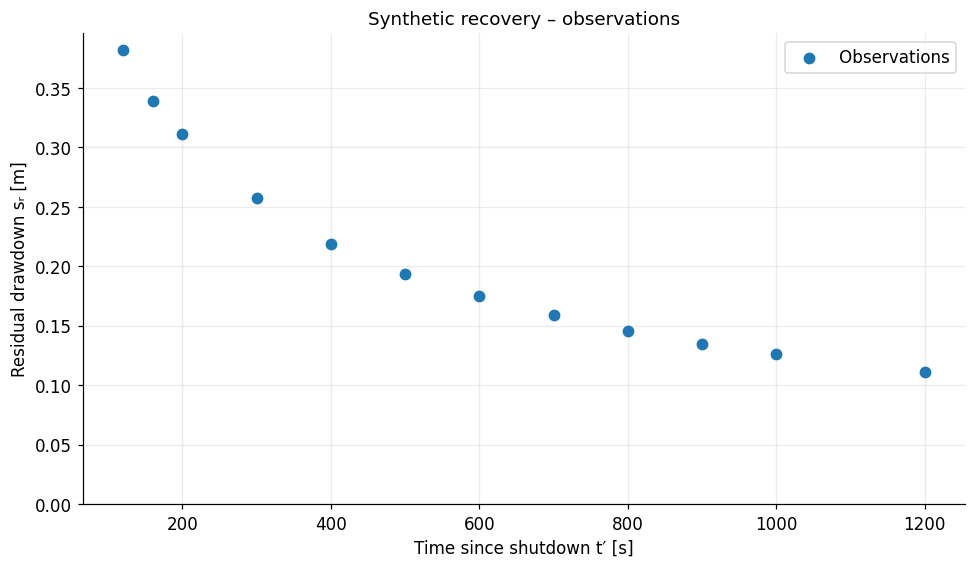

In [3]:
plot_linear(t_prime_syn, s_measured_syn, labels['lin_syn_title'])

### 3.2 Straight-line method – semi-logarithmic plot

For recovery analysis, plot **residual drawdown sᵣ** on a linear axis against the **time ratio t/t′** on a logarithmic axis. Regression provides the slope **m** and therefore **T**. Only the observations and fitted straight line are shown.

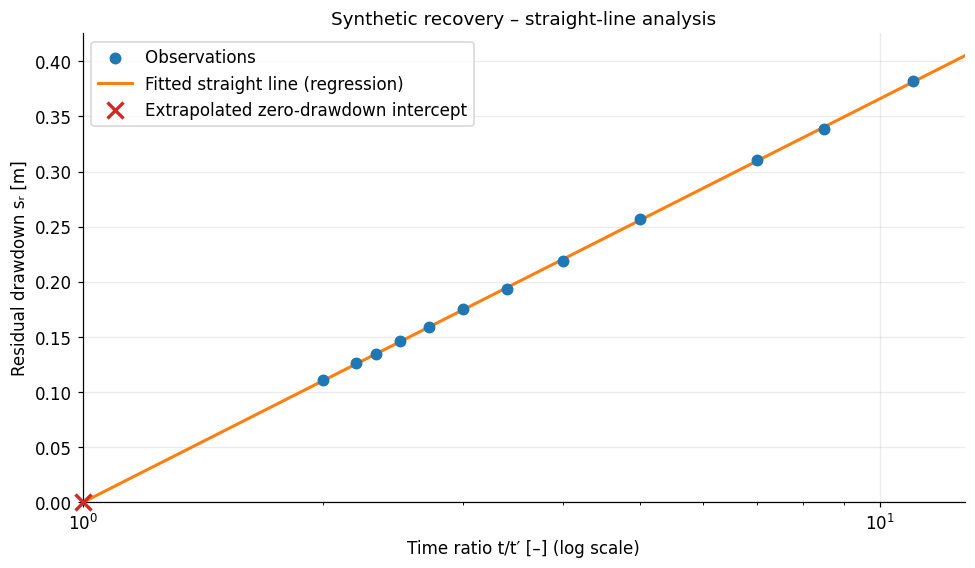

Synthetic recovery test
  Slope m = 0.36649 m/decade
  Intercept b = -0.00018 m
  Transmissivity T = 9.99939e-04 m²/s
  RMSE = 0.00104 m
  Zero intercept at t/t′ = 1.001
  Difference from input value = -0.01 %


In [4]:
fit_syn = recovery_straight_line(t_prime_syn, t_p_syn, Q_syn, s_measured_syn)
plot_recovery_fit(t_prime_syn, s_measured_syn, fit_syn, labels['fittitle_syn'])
print_results(labels['synthetic'], fit_syn)
print(f"  {labels['reldiff']} = "
      f"{100 * (fit_syn['transmissivity'] / T_syn - 1):+.2f} %")

### 3.3 Interpretation

For the synthetic data, the estimated transmissivity can be compared with the specified value. In real pumping tests, sufficiently late recovery measurements are preferable: a small RMSE alone does not demonstrate that the assumptions of the approximation are met.

## 4. Exercise – recovery measurements

We use the **16 observations from the exercise**. The pumping rate is **Q = 26.7 L/s**, and the observation well is **r = 27.4 m** from the pumping well. The time records indicate a constant pumping duration of **tₚ = 14,600 s**.

The aim is to determine **transmissivity T** using the recovery straight-line method.

In [5]:
# Exercise measurement data
Q_ex = 0.0267  # m³/s
r_ex = 27.4    # m (information; not required for the straight-line recovery formula)

t_ex = np.array([14765, 14823, 14871, 14920, 15235, 15332, 15600, 15810, 16180, 16400, 17300, 17900, 18560, 19220, 20700, 23300], dtype=float)       # s since pumping started
t_prime_ex = np.array([165, 223, 271, 320, 635, 732, 1000, 1210, 1580, 1800, 2700, 3300, 3960, 4620, 6100, 8700], dtype=float)  # s since shutdown
s_measured_ex = np.array([1.03, 0.95, 0.9, 0.85, 0.69, 0.65, 0.59, 0.55, 0.47, 0.44, 0.35, 0.3, 0.26, 0.23, 0.17, 0.09], dtype=float)  # m

pumping_durations = t_ex - t_prime_ex
if np.any(pumping_durations <= 0) or not np.allclose(pumping_durations, pumping_durations[0]):
    raise ValueError(labels['consistency'])
t_p_ex = float(pumping_durations[0])
print(f"{labels['duration']} = {t_p_ex:.0f} s")
print(f"{labels['exercise']}: {len(t_prime_ex)} {labels['observations']}")
print(labels['help'])


Pumping duration tₚ inferred from timestamps = 14600 s
Exercise: 16 Observations
These measurements are residual drawdowns, not the amount of water-level rise.


### 4.1 Observations – linear axes

Plot the observed **residual drawdown** against **t′**, the time elapsed since shutdown.

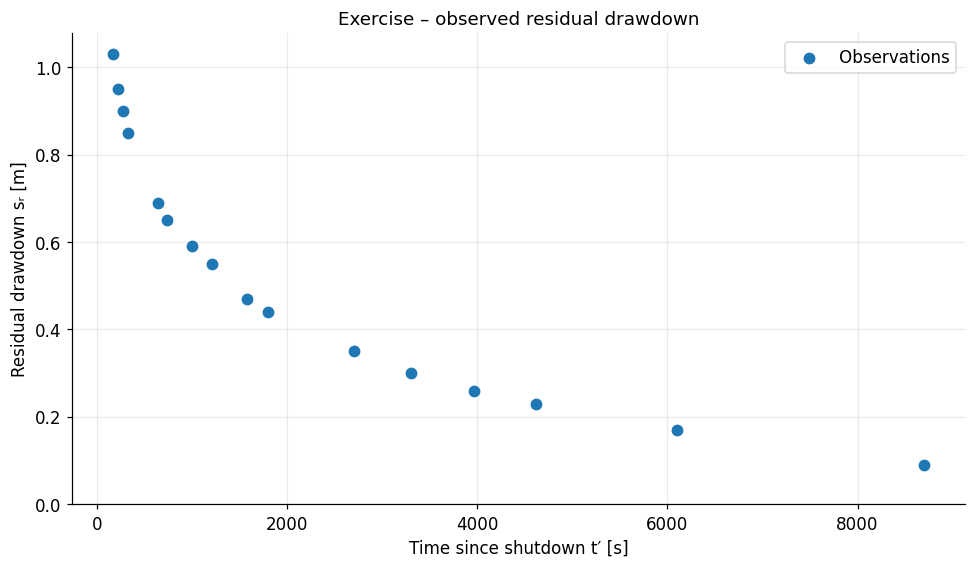

In [6]:
plot_linear(t_prime_ex, s_measured_ex, labels['lin_real_title'])

### 4.2 Recovery straight line – semi-logarithmic plot

The horizontal axis shows the **time ratio t/t′** logarithmically, starting at **10⁰ = 1**. The vertical axis shows **residual drawdown sᵣ** linearly and starts at **0 m**. A straight line is fitted to the observations and **T** is obtained from its slope. Its extrapolated intercept at **sᵣ = 0** is marked for reference; it is **not a radius of influence**.

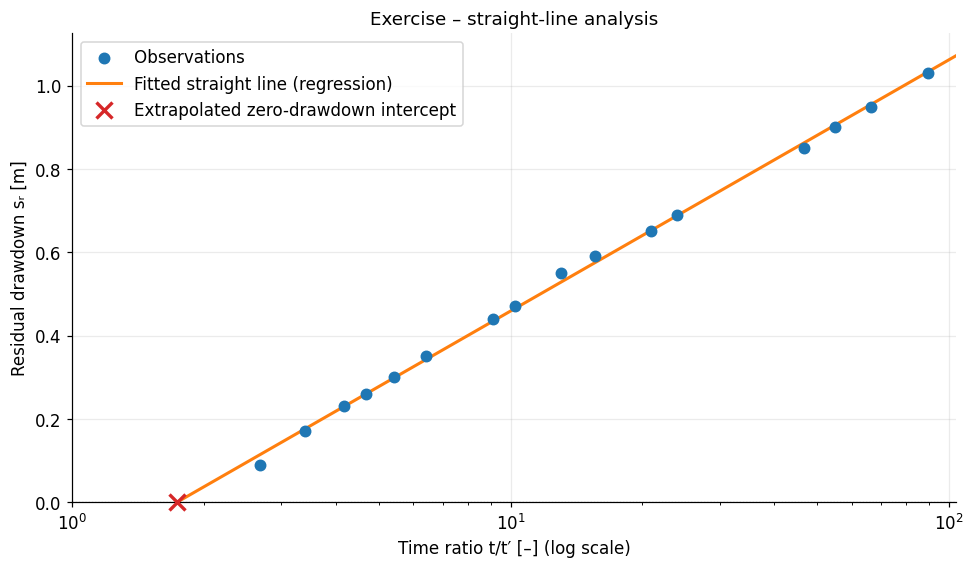

Exercise
  Slope m = 0.60331 m/decade
  Intercept b = -0.14442 m
  Transmissivity T = 8.10917e-03 m²/s
  RMSE = 0.00996 m
  Zero intercept at t/t′ = 1.735


In [7]:
fit_ex = recovery_straight_line(t_prime_ex, t_p_ex, Q_ex, s_measured_ex)
plot_recovery_fit(t_prime_ex, s_measured_ex, fit_ex, labels['fittitle_real'])
print_results(labels['exercise'], fit_ex)


### 4.3 Fit diagnostics

Residuals are **observed minus predicted** drawdown. Systematic patterns may indicate departures from the straight-line approximation. The exercise gives a manually selected slope of about **0.58 m per log cycle**, whereas regression yields about **0.603 m per log cycle**. Since **T is inversely proportional to the slope**, the higher slope gives a **lower transmissivity** (regression approximately **8.11 × 10⁻³ m²/s**, manual slope approximately **8.44 × 10⁻³ m²/s**).

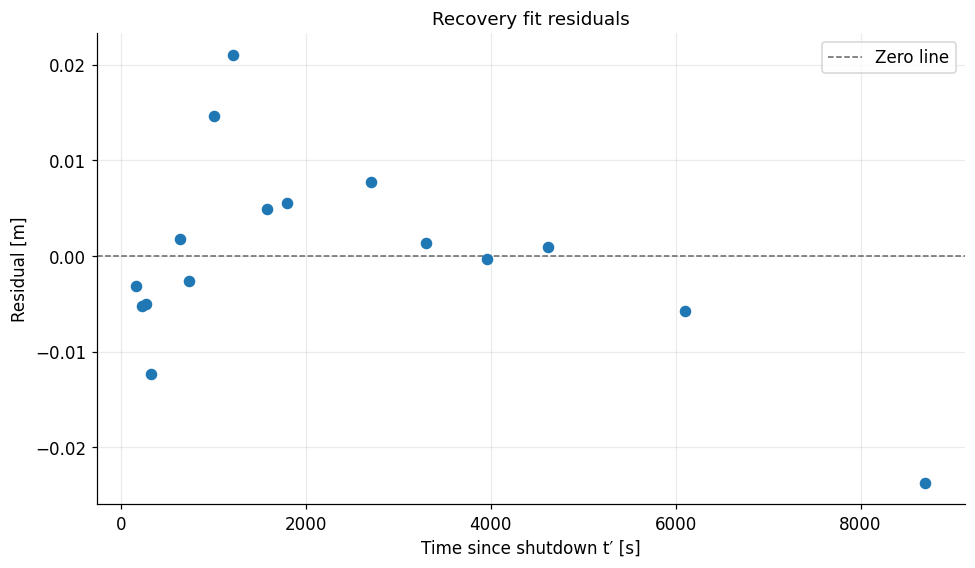

In [8]:
residuals = s_measured_ex - fit_ex['s_fit']
fig, ax = plt.subplots()
ax.scatter(t_prime_ex, residuals, s=43, color='C0', zorder=3)
ax.axhline(0, ls='--', lw=1, color='0.4', label=labels['linezero'])
ax.set(xlabel=labels['time'], ylabel=labels['restxt'], title=labels['restitle'])
ax.legend()
plt.tight_layout()
plt.show()


### 4.4 Independent check with `numpy.linalg.lstsq`

For verification, an independent least-squares calculation is used. Both methods must return the same slope, transmissivity and RMSE.

In [9]:
A = np.column_stack([fit_ex['log_ratio'], np.ones_like(fit_ex['log_ratio'])])
(slope_check, intercept_check), *_ = np.linalg.lstsq(A, s_measured_ex, rcond=None)
T_check = Q_ex * np.log(10) / (4 * np.pi * slope_check)
rmse_check = np.sqrt(np.mean((s_measured_ex - A @ [slope_check, intercept_check])**2))

print(labels['crosscheck'])
print(f"  {labels['slope']} = {slope_check:.5f} m/decade")
print(f"  {labels['axis']} = {intercept_check:.5f} m")
print(f"  {labels['trans']} = {T_check:.5e} m²/s")
print(f"  {labels['rmse']} = {rmse_check:.5f} m")
print(f"  {labels['difference']} = {T_check - fit_ex['transmissivity']:+.2e} m²/s")
assert np.isclose(T_check, fit_ex['transmissivity'], rtol=1e-12)
assert np.isclose(rmse_check, fit_ex['rmse'], rtol=1e-12)


Check using numpy.linalg.lstsq
  Slope m = 0.60331 m/decade
  Intercept b = -0.14442 m
  Transmissivity T = 8.10917e-03 m²/s
  RMSE = 0.00996 m
  Difference in T relative to numpy.polyfit = +3.47e-18 m²/s


## 5. Summary and limitations

| Step | Plot or calculation | Purpose |
|:--|:--|:--|
| Residual drawdown | linear **t′** and **sᵣ** | Inspect measurements |
| Recovery analysis | logarithmic **t/t′**, linear **sᵣ** | Estimate **T** from the slope |
| Residuals | linear axes | Assess fitting quality |

**Practical considerations:**

- **t** is time **since pumping began**, not just pumping duration: **t = tₚ + t′**.
- The classical recovery straight line requires **constant discharge** before shutdown and appropriate recovery times.
- Wellbore storage, background trends, aquifer boundaries and leakage may violate assumptions.
- **S** cannot be determined independently from the recovery straight-line method.
- The exercise input arrays may be replaced with observations from other tests.

## 6. References

- **Theis, C. V. (1935):** The relation between the lowering of the piezometric surface and the rate and duration of discharge of a well using ground-water storage. *Transactions, American Geophysical Union*, 16, 519–524. [DOI](https://doi.org/10.1029/TR016i002p00519).
- **Kruseman, G. P. & de Ridder, N. A. (1990; reprinted 1991):** *Analysis and Evaluation of Pumping Test Data*. 2nd edition, ILRI Publication 47, Wageningen. [The Groundwater Project](https://gw-project.org/books/analysis-and-evaluation-of-pumping-test-data/), especially Chapter 13.
- **Freeze, R. A. & Cherry, J. A. (1979):** *Groundwater*. Prentice-Hall. [The Groundwater Project](https://gw-project.org/books/groundwater/).
- **USGS:** *The Recovery Method for Determining the Coefficient of Transmissibility*. [Original report (PDF)](https://pubs.usgs.gov/wsp/1536i/report.pdf).

**Code acknowledgement:** Early programming examples were partly inspired by [Christian Hill's example](https://scipython.com/blog/linear-and-non-linear-fitting-of-the-theis-equation). The theory, analysis and presentation in this teaching notebook have been independently developed and reorganized.